# Chapter 7 — Support Vector Machines and Kernel Methods

**Book:** *scikit-learn Cookbook, Third Edition* — John Sukup (2025), Chapter 7.

This notebook studies the methods presented in the chapter through runnable Python examples, brief explanations of the underlying ideas, model diagnostics and interpretations of the outputs. Explanatory text is original; code samples are book-aligned demonstrations rather than a verbatim transcript of every recipe.

Run the cells in order in Google Colab.

In [1]:
import sklearn, numpy as np
print("scikit-learn version:", sklearn.__version__)

scikit-learn version: 1.6.1


## 1. Linear support vector classification

Support vector machines seek a separating boundary with a wide margin. Feature scaling is important because distances and margins are sensitive to predictor units.

In [2]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
X,y=load_iris(return_X_y=True)
A,B,c,d=train_test_split(X,y,random_state=42,stratify=y,test_size=.3)
linear=make_pipeline(StandardScaler(),SVC(kernel='linear',C=1)).fit(A,c)
print('Linear SVC accuracy:',round(accuracy_score(d,linear.predict(B)),3))

Linear SVC accuracy: 0.911


**Interpretation**

The hold-out score estimates how well a linear decision boundary distinguishes the three classes. A high score here does not imply a linear kernel will be best for every dataset.

## 2. Kernel functions

The kernel trick lets SVMs represent non-linear decision boundaries without explicitly creating all transformed features.

In [3]:
from sklearn.datasets import make_moons
Xm,ym=make_moons(n_samples=300,noise=.23,random_state=12)
A,B,c,d=train_test_split(Xm,ym,stratify=ym,test_size=.3,random_state=4)
for k in ['linear','poly','rbf']:
    s=make_pipeline(StandardScaler(),SVC(kernel=k,C=2,gamma='scale')).fit(A,c)
    print(k,'accuracy',round(s.score(B,d),3))

linear accuracy 0.933
poly accuracy 0.922
rbf accuracy 0.956


**Interpretation**

The two-moons data have curved class boundaries. Kernel choice matters because a linear separation may not capture this geometry, while non-linear kernels can.

## 3. Tuning C and gamma

C controls the penalty for margin violations. For RBF kernels, gamma affects how local the influence of training points becomes.

In [4]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
pipe=Pipeline([('scale',StandardScaler()),('svc',SVC(kernel='rbf'))])
search=GridSearchCV(pipe,{'svc__C':[.1,1,10], 'svc__gamma':[.01,.1,1]},cv=4)
search.fit(A,c)
print('Best settings:',search.best_params_)
print('Mean CV accuracy:',round(search.best_score_,3))
print('Test accuracy:',round(search.score(B,d),3))

Best settings: {'svc__C': 10, 'svc__gamma': 1}
Mean CV accuracy: 0.943
Test accuracy: 0.944


**Interpretation**

Validation folds are used to choose the combination, rather than optimizing the test set. Very large C or gamma can make the boundary overly sensitive to training points.

## 4. Visualizing decision regions

A two-dimensional mesh helps show how different SVM kernels assign labels to unseen positions.

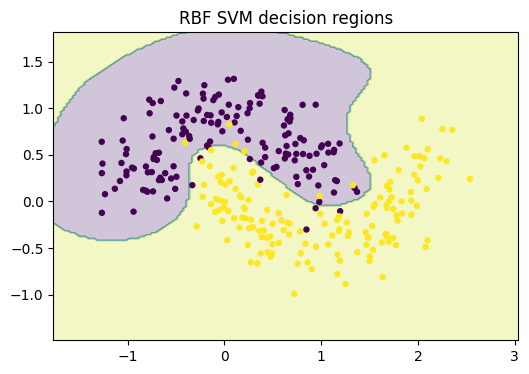

In [5]:
import numpy as np
import matplotlib.pyplot as plt
m=search.best_estimator_
xx,yy=np.meshgrid(np.linspace(Xm[:,0].min()-.5,Xm[:,0].max()+.5,160),np.linspace(Xm[:,1].min()-.5,Xm[:,1].max()+.5,160))
zz=m.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
plt.figure(figsize=(6,4));plt.contourf(xx,yy,zz,alpha=.25);plt.scatter(Xm[:,0],Xm[:,1],c=ym,s=13);plt.title('RBF SVM decision regions');plt.show()

**Interpretation**

The curved regions illustrate how an RBF kernel can adapt to a nonlinear shape. Points near the boundary are the cases most likely to be sensitive to noise.

## 5. Support vectors

Support vectors are the training observations most directly involved in defining the margin and decision function.

In [6]:
svc=search.best_estimator_.named_steps['svc']
print('Support vectors per class:',svc.n_support_)
print('Total support vectors:',len(svc.support_))
print('Training samples:',len(A))

Support vectors per class: [19 21]
Total support vectors: 40
Training samples: 210


**Interpretation**

Only a subset of training examples is identified as support vectors. Their number can increase when the data are noisy or the classes overlap.

## 6. High-dimensional text-like features

A linear SVM is often effective for high-dimensional sparse features, where an explicit nonlinear kernel may be too expensive.

In [7]:
from sklearn.datasets import make_classification
from sklearn.svm import LinearSVC
Xh,yh=make_classification(n_samples=350,n_features=150,n_informative=20,random_state=5)
A2,B2,c2,d2=train_test_split(Xh,yh,test_size=.25,random_state=5)
high=make_pipeline(StandardScaler(),LinearSVC(dual=False,max_iter=5000)).fit(A2,c2)
print('High-dimensional linear SVM test accuracy:',round(high.score(B2,d2),3))

High-dimensional linear SVM test accuracy: 0.557


**Interpretation**

This example keeps the model linear while allowing many predictors. The score shows generalization for the generated sample, not a universal guarantee about high-dimensional classification.

## 7. How the C parameter affects the margin

The soft-margin parameter C balances a wider margin against penalties for classification errors. With a small C, violations are tolerated more readily; a large C places more pressure on correctly classifying training samples.

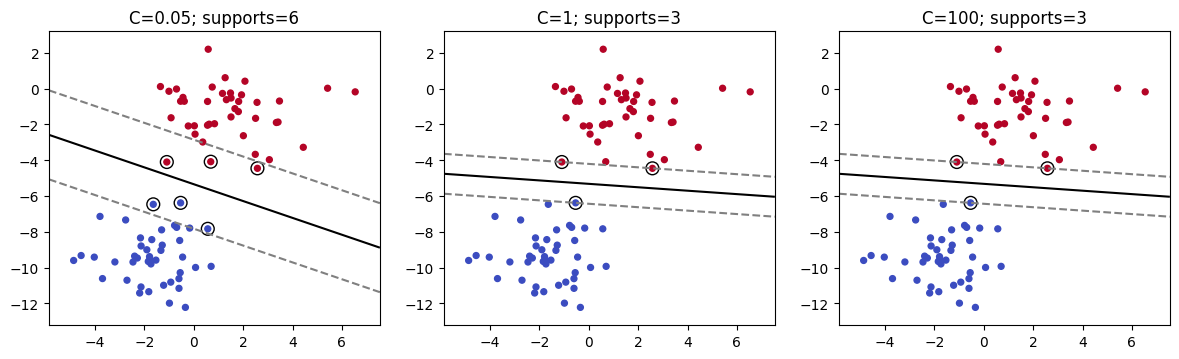

In [8]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.svm import SVC
Xp,yp=make_blobs(n_samples=85,centers=2,cluster_std=1.35,random_state=2)
fig,axes=plt.subplots(1,3,figsize=(12,3.7))
for ax,C in zip(axes,[.05,1,100]):
    fit=SVC(kernel='linear',C=C).fit(Xp,yp)
    gx,gy=np.meshgrid(np.linspace(Xp[:,0].min()-1,Xp[:,0].max()+1,120),np.linspace(Xp[:,1].min()-1,Xp[:,1].max()+1,120))
    decision=fit.decision_function(np.c_[gx.ravel(),gy.ravel()]).reshape(gx.shape)
    ax.contour(gx,gy,decision,levels=[-1,0,1],colors=['gray','black','gray'],linestyles=['--','-','--'])
    ax.scatter(Xp[:,0],Xp[:,1],c=yp,cmap='coolwarm',s=18)
    ax.scatter(fit.support_vectors_[:,0],fit.support_vectors_[:,1],s=85,facecolors='none',edgecolors='black')
    ax.set_title(f'C={C}; supports={len(fit.support_)}')
fig.tight_layout();plt.show()

**Interpretation**

The solid line is the separating boundary; dashed lines represent margins. Circled observations are support vectors. As C changes, the boundary and number of support vectors can change, demonstrating the trade-off between margin width and classification errors.

## 8. Comparing kernel settings with validation

Different kernels make different assumptions about the shape of the boundary. Comparing several kernels through cross-validation helps avoid choosing a model solely because it fits the training data.

In [9]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
cvs=StratifiedKFold(n_splits=5,shuffle=True,random_state=12)
for kernel in ['linear','poly','rbf','sigmoid']:
    cand=make_pipeline(StandardScaler(),SVC(kernel=kernel,C=2,gamma='scale'))
    scores=cross_val_score(cand,Xm,ym,cv=cvs,scoring='accuracy')
    print(f'{kernel:8s} mean={scores.mean():.3f}, std={scores.std():.3f}')

linear   mean=0.880, std=0.036
poly     mean=0.883, std=0.038
rbf      mean=0.937, std=0.027
sigmoid  mean=0.690, std=0.057


**Interpretation**

A kernel with a higher validation average is more promising for this dataset, but the spread across folds indicates uncertainty. The scores are specific to the data and chosen hyperparameters rather than a universal ranking of kernels.

## 9. Feature scaling and the SVM

Distance-sensitive models respond to feature magnitudes. If one predictor is measured on a scale hundreds of times larger than another, it may dominate the fitted boundary unless the inputs are standardized.

In [10]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
Xscale,yscale=load_breast_cancer(return_X_y=True)
Xa,Xb,ya,yb=train_test_split(Xscale,yscale,test_size=.25,stratify=yscale,random_state=17)
raw=SVC(kernel='rbf',C=1).fit(Xa,ya)
scaled=make_pipeline(StandardScaler(),SVC(kernel='rbf',C=1)).fit(Xa,ya)
print('Unscaled test accuracy:',round(raw.score(Xb,yb),3))
print('Scaled test accuracy:',round(scaled.score(Xb,yb),3))

Unscaled test accuracy: 0.944
Scaled test accuracy: 1.0


**Interpretation**

These two models use the same training split and algorithm but differ in preprocessing. A difference in scores shows how input units can affect the RBF distance calculation. Scaling must be learned from training data only, which the pipeline handles correctly.

## 10. SVM regression with an epsilon-insensitive tube

Support vector regression (SVR) extends the same optimization family to continuous targets. The epsilon parameter defines a band where small prediction errors are not penalized, while C controls the penalty for larger deviations.

epsilon=0.05: train MAE=0.095
epsilon=0.3: train MAE=0.116


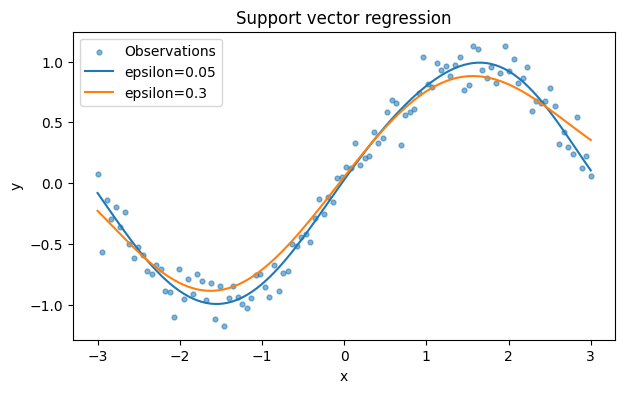

In [11]:
from sklearn.svm import SVR
rng=np.random.default_rng(13)
xreg=np.linspace(-3,3,110)
yreg=np.sin(xreg)+rng.normal(0,.12,len(xreg))
fig,ax=plt.subplots(figsize=(7,4))
ax.scatter(xreg,yreg,s=12,alpha=.55,label='Observations')
for epsilon in [.05,.3]:
    svr=make_pipeline(StandardScaler(),SVR(kernel='rbf',C=5,epsilon=epsilon)).fit(xreg.reshape(-1,1),yreg)
    yhat=svr.predict(xreg.reshape(-1,1))
    ax.plot(xreg,yhat,label=f'epsilon={epsilon}')
    print(f'epsilon={epsilon}: train MAE={np.mean(np.abs(yreg-yhat)):.3f}')
ax.set(title='Support vector regression',xlabel='x',ylabel='y');ax.legend();plt.show()

**Interpretation**

The fitted curves approximate the underlying nonlinear relationship. A larger epsilon makes the model less sensitive to small deviations and may produce a smoother fit at the expense of local accuracy. Training MAE is not a substitute for evaluating on new observations.

## 11. Linear SVM margin and support vectors

A linear SVM looks for a decision boundary with a large margin between classes. Support vectors are training points that directly determine the margin and thus exert a disproportionate influence on the fitted classifier.

In [12]:
import numpy as np
from sklearn.datasets import make_blobs
from sklearn.svm import SVC
Xs,ys=make_blobs(n_samples=120,centers=2,cluster_std=1.6,random_state=8)
linear=SVC(kernel='linear',C=1).fit(Xs,ys)
print('Training accuracy:',round(linear.score(Xs,ys),3))
print('Support vectors per class:',linear.n_support_.tolist())
print('Coefficients:',np.round(linear.coef_[0],3))

Training accuracy: 1.0
Support vectors per class: [1, 2]
Coefficients: [ 0.521 -0.825]


**Interpretation**

Only a subset of observations are support vectors. Their count gives a sense of how many points participate in constraining the margin, while the coefficients identify the orientation of the linear separating boundary.

## 12. Distance to the separating hyperplane

The decision_function provides signed scores relative to the separating boundary. For a linear kernel, dividing the absolute score by the coefficient vector norm gives the geometric distance to the fitted hyperplane.

In [13]:
score=linear.decision_function(Xs[:8]);norm=np.linalg.norm(linear.coef_)
for i,val in enumerate(score):
    print(f'point={i} signed score={val:+.3f} distance={abs(val)/norm:.3f}')

point=0 signed score=+3.635 distance=3.727
point=1 signed score=-1.367 distance=1.402
point=2 signed score=+4.359 distance=4.470
point=3 signed score=-2.504 distance=2.567
point=4 signed score=-2.637 distance=2.704
point=5 signed score=+2.975 distance=3.050
point=6 signed score=+3.805 distance=3.902
point=7 signed score=+4.561 distance=4.677


**Interpretation**

Points with small distances lie near the classifier boundary and may be more sensitive to small perturbations. A large decision score does not equal a probability; probability calibration is a separate step.

## 13. Polynomial kernels and degree

A polynomial kernel allows curved relationships by considering feature interactions implicitly. The degree parameter changes the complexity of the induced decision boundary.

In [14]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
Xmoon,ymoon=make_moons(n_samples=450,noise=.22,random_state=21)
At,Bt,ct,dt=train_test_split(Xmoon,ymoon,test_size=.3,stratify=ymoon,random_state=21)
for degree in [2,3,4,6]:
    m=make_pipeline(StandardScaler(),SVC(kernel='poly',degree=degree,C=2,gamma='scale')).fit(At,ct)
    print('degree:',degree,'training:',round(m.score(At,ct),3),'test:',round(m.score(Bt,dt),3))

degree: 2 training: 0.505 test: 0.504
degree: 3 training: 0.876 test: 0.881
degree: 4 training: 0.505 test: 0.489
degree: 6 training: 0.524 test: 0.519


**Interpretation**

Increasing degree provides greater flexibility, but it does not guarantee higher test accuracy. A widening train/test gap can indicate that the boundary is fitting fine details rather than general structure.

## 14. RBF gamma and local flexibility

The gamma parameter determines how local each training point’s influence is in the radial basis function kernel. Very high gamma often produces highly detailed boundaries; low gamma tends to yield smoother decisions.

In [15]:
for gamma in [.01,.1,1,10,100]:
    m=make_pipeline(StandardScaler(),SVC(kernel='rbf',gamma=gamma,C=2)).fit(At,ct)
    print(f'gamma={gamma:>6}: train={m.score(At,ct):.3f}, test={m.score(Bt,dt):.3f}')

gamma=  0.01: train=0.857, test=0.867
gamma=   0.1: train=0.883, test=0.896
gamma=     1: train=0.949, test=0.926
gamma=    10: train=0.959, test=0.919
gamma=   100: train=0.997, test=0.889


**Interpretation**

The scores demonstrate the bias–variance trade-off of gamma. A model that perfectly fits the training points but loses accuracy on the held-out set is not necessarily the best choice.

## 15. Grid search for both C and gamma

The best C value can depend on gamma, so tuning them independently may miss effective combinations. Cross-validation over a small parameter grid makes the comparison repeatable.

In [16]:
from sklearn.model_selection import GridSearchCV
svm_pipe=make_pipeline(StandardScaler(),SVC(kernel='rbf'))
svm_search=GridSearchCV(svm_pipe,{'svc__C':[.1,1,10,100],'svc__gamma':[.01,.1,1]},cv=4,n_jobs=-1).fit(At,ct)
print('Best parameters:',svm_search.best_params_)
print('Cross-validation accuracy:',round(svm_search.best_score_,3))
print('Held-out accuracy:',round(svm_search.score(Bt,dt),3))

Best parameters: {'svc__C': 10, 'svc__gamma': 1}
Cross-validation accuracy: 0.943
Held-out accuracy: 0.911


**Interpretation**

The search uses validation folds to choose the parameter pair. The held-out accuracy provides a more independent estimate of how the selected model performs than the training score.

## 16. Kernel choice on nonlinear data

A linear boundary may struggle with curved class structures. Comparing linear, polynomial, and RBF kernels on exactly the same split makes the differences in model flexibility visible.

In [17]:
for kernel in ['linear','poly','rbf']:
    m=make_pipeline(StandardScaler(),SVC(kernel=kernel,C=2,gamma='scale')).fit(At,ct)
    print(f'{kernel}: train accuracy={m.score(At,ct):.3f}, test accuracy={m.score(Bt,dt):.3f}')

linear: train accuracy=0.860, test accuracy=0.867
poly: train accuracy=0.876, test accuracy=0.881
rbf: train accuracy=0.946, test accuracy=0.926


**Interpretation**

The two-moons dataset has a curved structure. A nonlinear kernel may follow the pattern more naturally than a straight boundary, but added flexibility must be judged using test performance.

## 17. Class weighting for imbalanced SVM

With imbalanced classes, predicting the majority class can yield a misleadingly high accuracy. The class_weight parameter changes the cost of mistakes in minority and majority groups.

In [18]:
from sklearn.datasets import make_classification
from sklearn.metrics import classification_report
Xi,yi=make_classification(n_samples=550,n_features=12,weights=[.91,.09],random_state=34)
Xi_a,Xi_b,yi_a,yi_b=train_test_split(Xi,yi,test_size=.3,stratify=yi,random_state=34)
for weight in [None,'balanced']:
    m=make_pipeline(StandardScaler(),SVC(class_weight=weight,C=1)).fit(Xi_a,yi_a)
    print('Class weight:',weight)
    print(classification_report(yi_b,m.predict(Xi_b),zero_division=0,digits=3))

Class weight: None
              precision    recall  f1-score   support

           0      0.980     0.987     0.983       150
           1      0.857     0.800     0.828        15

    accuracy                          0.970       165
   macro avg      0.919     0.893     0.905       165
weighted avg      0.969     0.970     0.969       165

Class weight: balanced
              precision    recall  f1-score   support

           0      0.986     0.967     0.976       150
           1      0.722     0.867     0.788        15

    accuracy                          0.958       165
   macro avg      0.854     0.917     0.882       165
weighted avg      0.962     0.958     0.959       165



**Interpretation**

Balancing may improve minority recall, often at a cost in precision or majority-class accuracy. These trade-offs should be evaluated against the real consequences of the two error types.

## 18. Multiclass SVM with Iris

SVMs can handle more than two classes. scikit-learn uses pairwise classification internally for SVC, while providing predictions through the same fit/predict interface.

In [19]:
from sklearn.datasets import load_iris
from sklearn.metrics import confusion_matrix
iris=load_iris()
Ai,Bi,ci,di=train_test_split(iris.data,iris.target,test_size=.3,stratify=iris.target,random_state=19)
svm_iris=make_pipeline(StandardScaler(),SVC(kernel='rbf',C=3)).fit(Ai,ci)
print('Accuracy:',round(svm_iris.score(Bi,di),3))
print('Confusion matrix: ',confusion_matrix(di,svm_iris.predict(Bi)))

Accuracy: 1.0
Confusion matrix:  [[15  0  0]
 [ 0 15  0]
 [ 0  0 15]]


**Interpretation**

Correct predictions appear on the diagonal of the matrix. Errors between species show which categories the feature representation does not separate as reliably.

## 19. SVM model evaluation using cross-validation

Performance estimates from one split can be unusually high or low depending on the samples selected. Stratified cross-validation provides a broader view of the model’s variability.

In [20]:
from sklearn.model_selection import StratifiedKFold,cross_validate
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=19)
scores=cross_validate(make_pipeline(StandardScaler(),SVC(kernel='rbf',C=3)),iris.data,iris.target,cv=cv,scoring=['accuracy','f1_macro'])
for k in ['accuracy','f1_macro']:
    vals=scores['test_'+k]
    print(f'{k}: mean={vals.mean():.3f}, std={vals.std():.3f}')

accuracy: mean=0.953, std=0.045
f1_macro: mean=0.953, std=0.045


**Interpretation**

The mean summarizes performance across folds, while the standard deviation shows dependence on the chosen validation partition. Macro F1 also checks that performance is not solely driven by one class.

## 20. Support vectors and model complexity

The number of support vectors can change with the value of C. Examining support vector counts across settings provides another way to understand how the decision boundary is constrained by observations.

In [21]:
for cval in [.01,.1,1,10,100]:
    model=SVC(kernel='rbf',C=cval,gamma='scale').fit(At,ct)
    print(f'C={cval:<6}: support_vectors={len(model.support_):3d}, test_accuracy={model.score(Bt,dt):.3f}')

C=0.01  : support_vectors=314, test_accuracy=0.763
C=0.1   : support_vectors=164, test_accuracy=0.896
C=1     : support_vectors= 82, test_accuracy=0.926
C=10    : support_vectors= 49, test_accuracy=0.911
C=100   : support_vectors= 40, test_accuracy=0.911


**Interpretation**

Fewer support vectors can reflect a more economical decision rule, but the count alone is not a reliable measure of generalization. The validation or test performance is needed to judge whether the changes help.